# HackINE — 05 · Auditoría de identidad municipal

**Fuente:** INE CCPC 2009–2024, bases adjuntas. No hay datos personales.

## Pregunta de investigación
¿Podemos afirmar que la identidad de cada municipio es comparable a lo largo de las seis elecciones? **No**: la coincidencia de clave y nombre no valida límites geográficos. Aquí se documenta una aproximación conservadora.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
p=Path('datos/processed/producto')
a=pd.read_csv(p/'homologacion_municipal_auditoria.csv')
a.estatus_administrativo.value_counts()

estatus_administrativo
estable_por_nombre_y_clave    2423
revisar_identidad_nominal       32
incompleto_en_serie             22
Name: count, dtype: int64

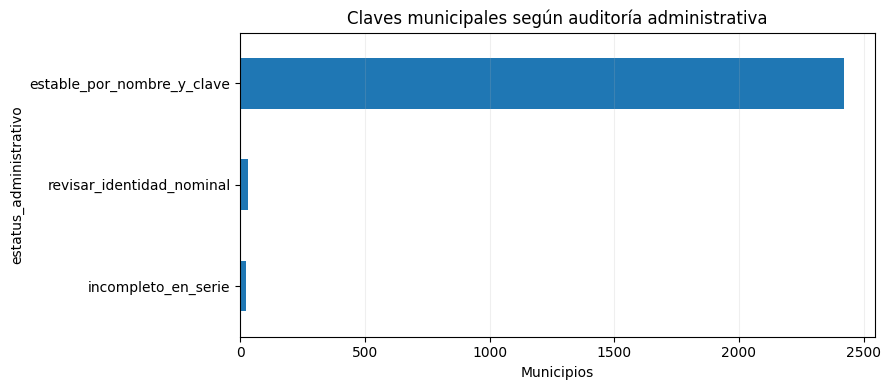

In [2]:
counts=a.estatus_administrativo.value_counts().sort_values()
fig,ax=plt.subplots(figsize=(9,4));counts.plot.barh(ax=ax);ax.set_title('Claves municipales según auditoría administrativa');ax.set_xlabel('Municipios');ax.grid(axis='x',alpha=.2);plt.tight_layout();plt.show()

## Casos delicados
Se muestran claves cuyo nombre y/o presencia histórica difieren. Esto NO autoriza a unir claves distintas ni a interpolar municipios nuevos.

In [3]:
a[a.estatus_administrativo.ne('estable_por_nombre_y_clave')][['clave_municipal','EDONOM','MPIONOM','anios_observados','nombres','estatus_administrativo']].head(15)

,clave_municipal,EDONOM,MPIONOM,anios_observados,nombres,estatus_administrativo
16,02-006,BAJA CALIFORNIA,San Quintin,1,San Quintin,incompleto_en_serie
17,02-007,BAJA CALIFORNIA,San Felipe,1,San Felipe,incompleto_en_serie
28,04-006,CAMPECHE,Hopelche}én,6,Hopelche}én | Hopelchén,revisar_identidad_nominal
34,04-012,CAMPECHE,Dzitbalché,2,Dzitbalché | Dzitblache,incompleto_en_serie
35,04-013,CAMPECHE,Seybaplaya,2,Seybaplaya,incompleto_en_serie
121,07-038,CHIAPAS,Huitiupaán,6,Huitiupaán | Huitiupán,revisar_identidad_nominal
197,07-114,CHIAPAS,Maravilla Tenejapa,6,Maravilla Tejenapa | Maravilla Tenejapa,revisar_identidad_nominal
200,07-117,CHIAPAS,San Andrés Duraznal,5,San Andrés Duraznal,incompleto_en_serie
202,07-119,CHIAPAS,Capitán Luis Ángel Vidal,2,Capitán Luis Ángel Vidal,incompleto_en_serie
203,07-120,CHIAPAS,Rincón Chamula San Pedro,3,Emiliano Zapata | Rincón Chamula San Pedro,incompleto_en_serie


## Tasa de inclusión del clustering
Este filtro no elimina el riesgo de cambios en límites. La cobertura y el sesgo deben evaluarse antes de usar resultados institucionalmente.

In [4]:
panel=pd.read_csv('datos/processed/matriz_modelo_6_anios.csv')
print('unidades panel',len(panel),'aptas',int(panel.apto_modelo.sum()))
print('porcentaje aptas',round(100*panel.apto_modelo.mean(),1),'%')
print('nombres no estables',len(a[a.variantes_normalizadas.gt(1)]))

unidades panel 12385 aptas 8541
porcentaje aptas 69.0 %
nombres no estables 38


## Conclusión
La homologación administrativa queda auditable y reproducible. **La equivalencia cartográfica histórica continúa pendiente**; ver `docs/07_homologacion_territorial.md`.